In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("Fruit Counting Project Started!")

OpenCV version: 5.0.0
Fruit Counting Project Started!


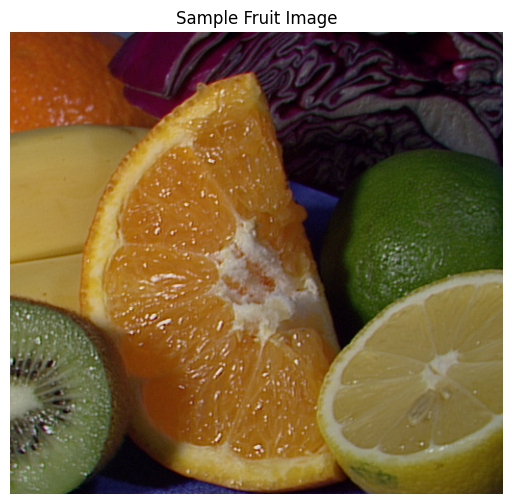

Image loaded successfully!
Image dimensions: (480, 512, 3)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download a sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg"

urllib.request.urlretrieve(url, "fruits.jpg")

# Read the image
img = cv2.imread("fruits.jpg")

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.title("Sample Fruit Image")
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")
    print("Image dimensions:", img.shape)
else:
    print("Image could not be loaded.")

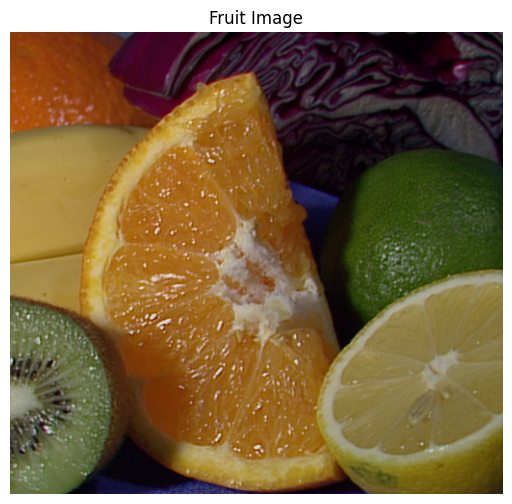

Image loaded successfully!


In [ ]:
import cv2
import matplotlib.pyplot as plt
import urllib.request

# Download one sample image automatically
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg"

urllib.request.urlretrieve(url, "/content/fruits.jpg")

# Load and display the image
img = cv2.imread("/content/fruits.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Fruit Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")

In [ ]:
import zipfile
import os

zip_path = "/content/your_dataset.zip"
extract_path = "/content/fruit_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

FileNotFoundError: [Errno 2] No such file or directory: '/content/your_dataset.zip'

In [ ]:
import os

files = os.listdir("/content")

print("Files in Colab:")
for file in files:
    print(file)

Files in Colab:
.config
fruits.jpg
sample_data


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (4).zip to archive (4).zip


In [ ]:
import zipfile
import os

zip_path = "/content/archive (4).zip"
extract_path = "/content/fruit_dataset"

print("Extracting dataset... Please wait.")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print("\nFiles and folders inside the dataset:")
for item in os.listdir(extract_path):
    print(item)

Extracting dataset... Please wait.
Dataset extracted successfully!

Files and folders inside the dataset:
images


In [ ]:
import os

# Dataset images folder
images_path = "/content/fruit_dataset/images"

# List files and folders
for root, dirs, files in os.walk(images_path):
    print("Folder:", root)
    print("Number of files:", len(files))

    for name in files[:10]:
        print("  ", name)

    if root.count(os.sep) - images_path.count(os.sep) >= 2:
        dirs.clear()

Folder: /content/fruit_dataset/images
Number of files: 0
Folder: /content/fruit_dataset/images/kiwi fruit
Number of files: 40
   Image_11.jpg
   Image_32.jpg
   Image_6.jpg
   Image_16.jpg
   Image_28.jpg
   Image_9.jpg
   Image_40.jpg
   Image_10.jpg
   Image_15.jpg
   Image_7.jpg
Folder: /content/fruit_dataset/images/grapes fruit
Number of files: 40
   Image_3.jpeg
   Image_11.jpg
   Image_32.jpg
   Image_18.jpg
   Image_6.jpg
   Image_16.jpg
   Image_28.jpg
   Image_21.jpg
   Image_9.jpg
   Image_36.jpeg
Folder: /content/fruit_dataset/images/mango fruit
Number of files: 40
   Image_11.jpg
   Image_32.jpg
   Image_6.jpg
   Image_16.jpg
   Image_28.jpg
   Image_21.jpg
   Image_9.jpg
   Image_40.jpg
   Image_1.jpg
   Image_15.jpg
Folder: /content/fruit_dataset/images/orange fruit
Number of files: 40
   Image_32.jpg
   Image_18.jpg
   Image_6.jpg
   Image_16.jpg
   Image_28.jpg
   Image_21.jpg
   Image_9.jpg
   Image_40.jpg
   Image_1.jpg
   Image_10.jpg
Folder: /content/fruit_dataset/i

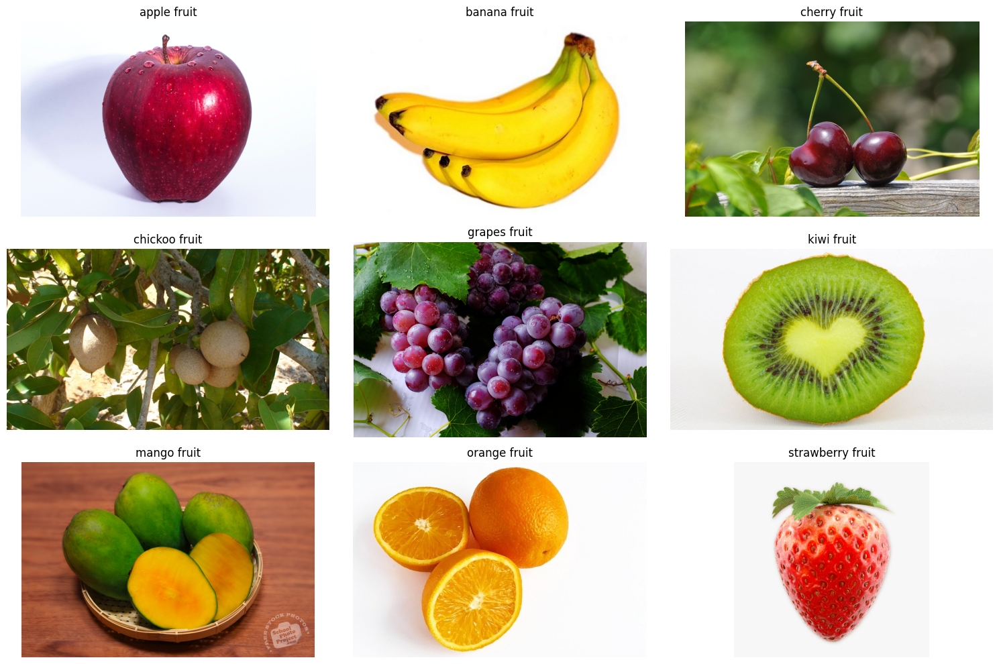

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

fruit_folders = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

plt.figure(figsize=(15, 10))

for i, folder in enumerate(sorted(fruit_folders)):
    folder_path = os.path.join(dataset_path, folder)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if not image_files:
        continue

    image_path = os.path.join(folder_path, image_files[0])
    image = cv2.imread(image_path)

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(3, 3, i + 1)
        plt.imshow(image)
        plt.title(folder)
        plt.axis("off")

plt.tight_layout()
plt.show()

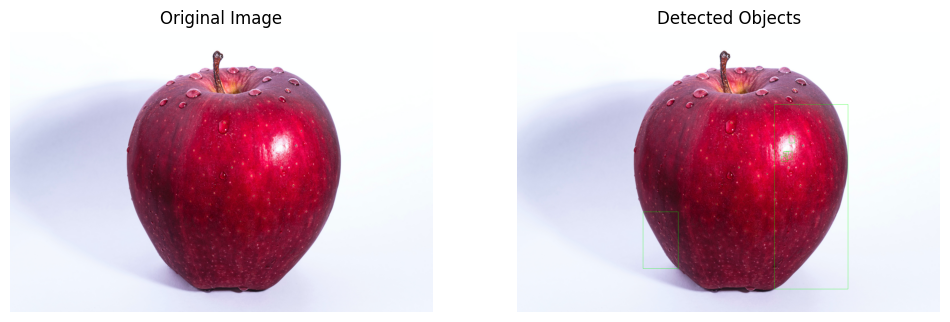

Detected objects: 6


In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# Select a fruit category
dataset_path = "/content/fruit_dataset/images"
fruit_folder = "apple fruit"

folder_path = os.path.join(dataset_path, fruit_folder)
image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Load one image
image_path = os.path.join(folder_path, image_files[0])
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to grayscale and blur
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
edges = cv2.Canny(blur, 50, 150)

# Find contours
contours, _ = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Draw contours around large objects
result = image_rgb.copy()
count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 300:
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(
            result, (x, y), (x + w, y + h), (0, 255, 0), 2
        )
        count += 1

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Detected Objects")
plt.axis("off")

plt.show()

print("Detected objects:", count)

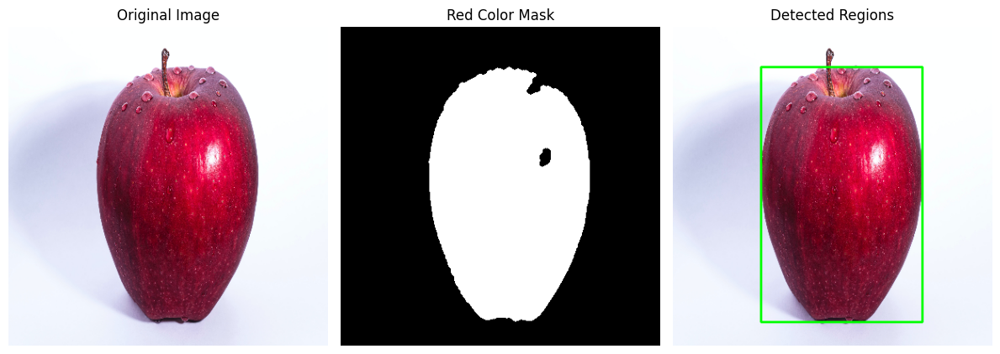

Detected red regions: 1


In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"
folder_path = os.path.join(dataset_path, "apple fruit")

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(folder_path, image_files[0])
image = cv2.imread(image_path)

# Resize for easier processing
image = cv2.resize(image, (400, 400))
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to HSV color space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Create a mask for common red apple colors
lower_red1 = (0, 50, 40)
upper_red1 = (15, 255, 255)
lower_red2 = (160, 50, 40)
upper_red2 = (180, 255, 255)

mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
mask = cv2.bitwise_or(mask1, mask2)

# Clean small noisy regions
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# Find fruit-colored regions
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

result = rgb.copy()
count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 500:
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(result, (x, y), (x+w, y+h), (0, 255, 0), 2)
        count += 1

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Red Color Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title("Detected Regions")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Detected red regions:", count)

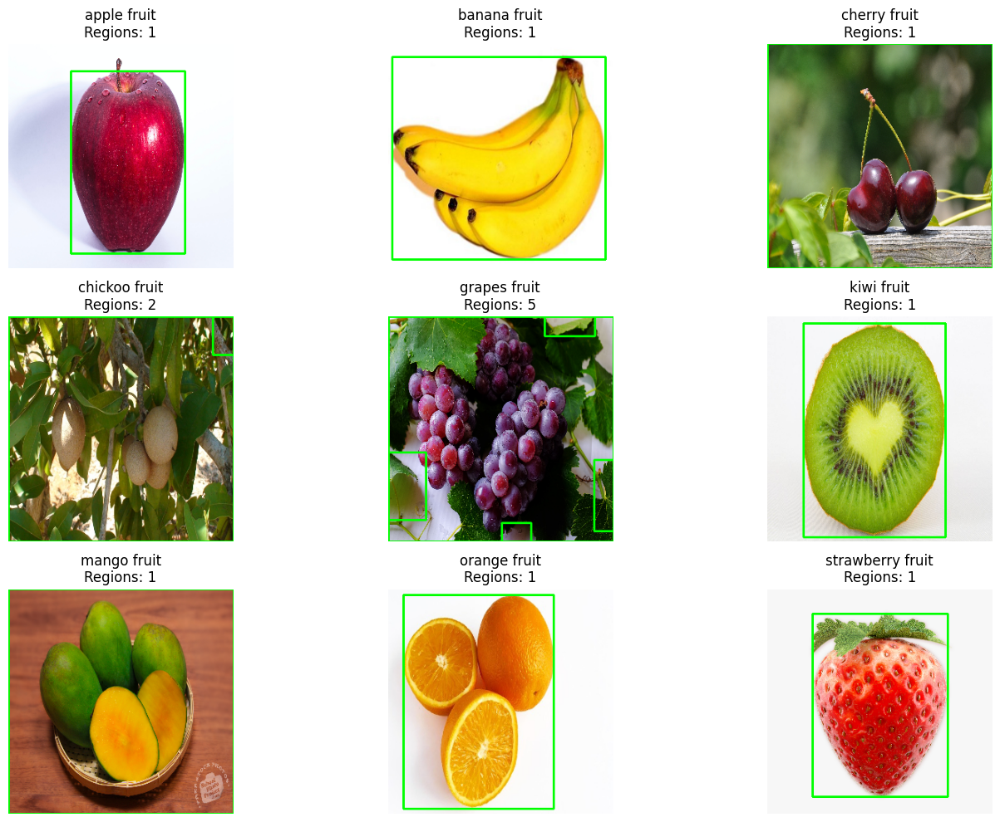

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

fruit_folders = sorted([
    f for f in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, f))
])

plt.figure(figsize=(15, 10))

for i, fruit in enumerate(fruit_folders):
    folder_path = os.path.join(dataset_path, fruit)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if not image_files:
        continue

    image_path = os.path.join(folder_path, image_files[0])
    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.resize(image, (300, 300))
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Detect a broad range of fruit colors
    mask = cv2.inRange(
        hsv,
        (0, 40, 30),
        (180, 255, 255)
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (7, 7)
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    result = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                result, (x, y), (x+w, y+h), (0, 255, 0), 2
            )
            count += 1

    plt.subplot(3, 3, i + 1)
    plt.imshow(result)
    plt.title(f"{fruit}\nRegions: {count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import pandas as pd

dataset_path = "/content/fruit_dataset/images"

results = []

for fruit in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, fruit)

    if not os.path.isdir(folder_path):
        continue

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    readable = 0

    for filename in image_files:
        path = os.path.join(folder_path, filename)
        image = cv2.imread(path)

        if image is not None:
            readable += 1

    results.append({
        "Fruit Category": fruit,
        "Total Images": len(image_files),
        "Readable Images": readable
    })

df = pd.DataFrame(results)

print(df.to_string(index=False))
print("\nTotal images:", df["Total Images"].sum())
print("Total readable images:", df["Readable Images"].sum())

  Fruit Category  Total Images  Readable Images
     apple fruit            40               40
    banana fruit            40               40
    cherry fruit            40               40
   chickoo fruit            40               40
    grapes fruit            40               40
      kiwi fruit            40               40
     mango fruit            39               39
    orange fruit            40               40
strawberry fruit            40               40

Total images: 359
Total readable images: 359


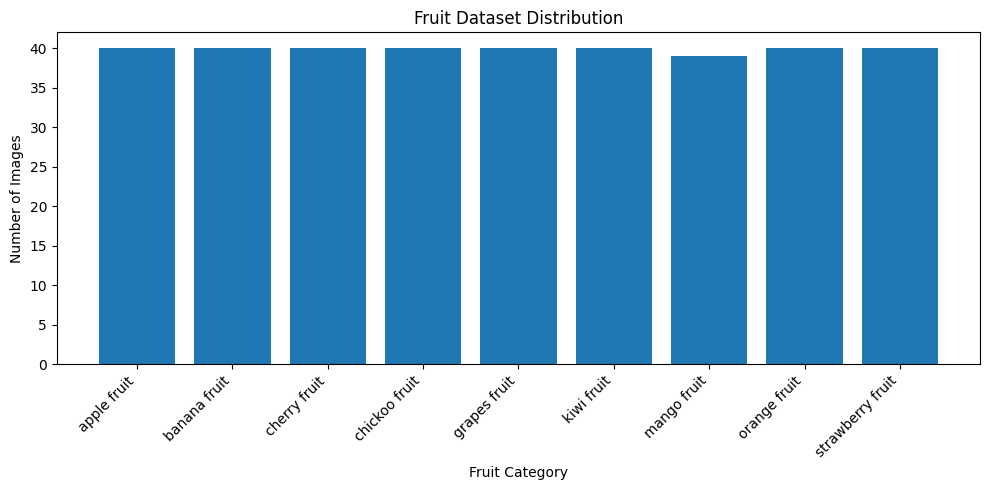

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    df["Fruit Category"],
    df["Total Images"]
)

plt.title("Fruit Dataset Distribution")
plt.xlabel("Fruit Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

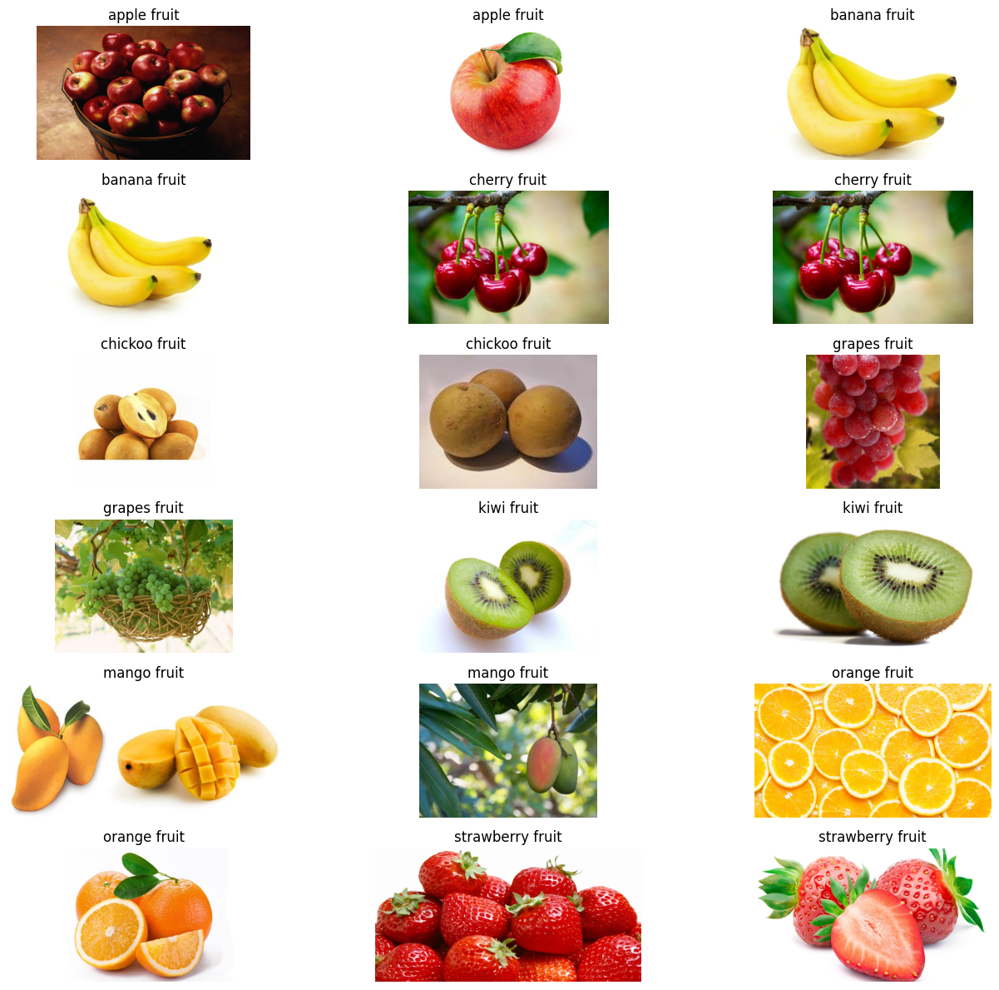

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

dataset_path = "/content/fruit_dataset/images"

# Reproducible sample selection
random.seed(42)

fruit_folders = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

plt.figure(figsize=(14, 12))
plot_index = 1

for fruit in fruit_folders:
    folder_path = os.path.join(dataset_path, fruit)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Select up to 2 images from each category
    selected = random.sample(
        image_files, min(2, len(image_files))
    )

    for filename in selected:
        image_path = os.path.join(folder_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(6, 3, plot_index)
        plt.imshow(image)
        plt.title(fruit)
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

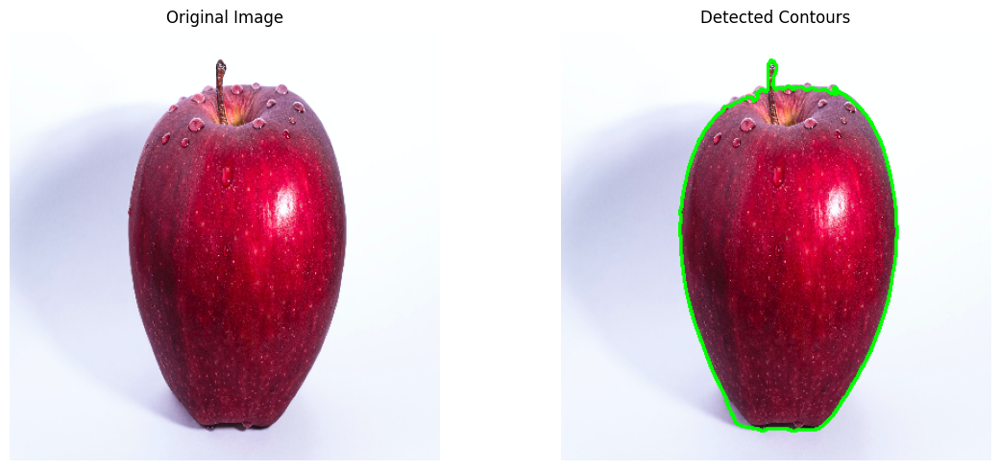

Large contours detected: 1


In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# Select an apple image
folder = "/content/fruit_dataset/images/apple fruit"

files = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(folder, files[0])
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Resize while preserving the aspect ratio
image = cv2.resize(image, (400, 400))

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Smooth the image
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Threshold the image automatically
_, thresh = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Find external contours
contours, _ = cv2.findContours(
    thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Draw contours larger than the minimum area
result = image.copy()
count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 500:
        cv2.drawContours(result, [contour], -1, (0, 255, 0), 2)
        count += 1

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Contours")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Large contours detected:", count)

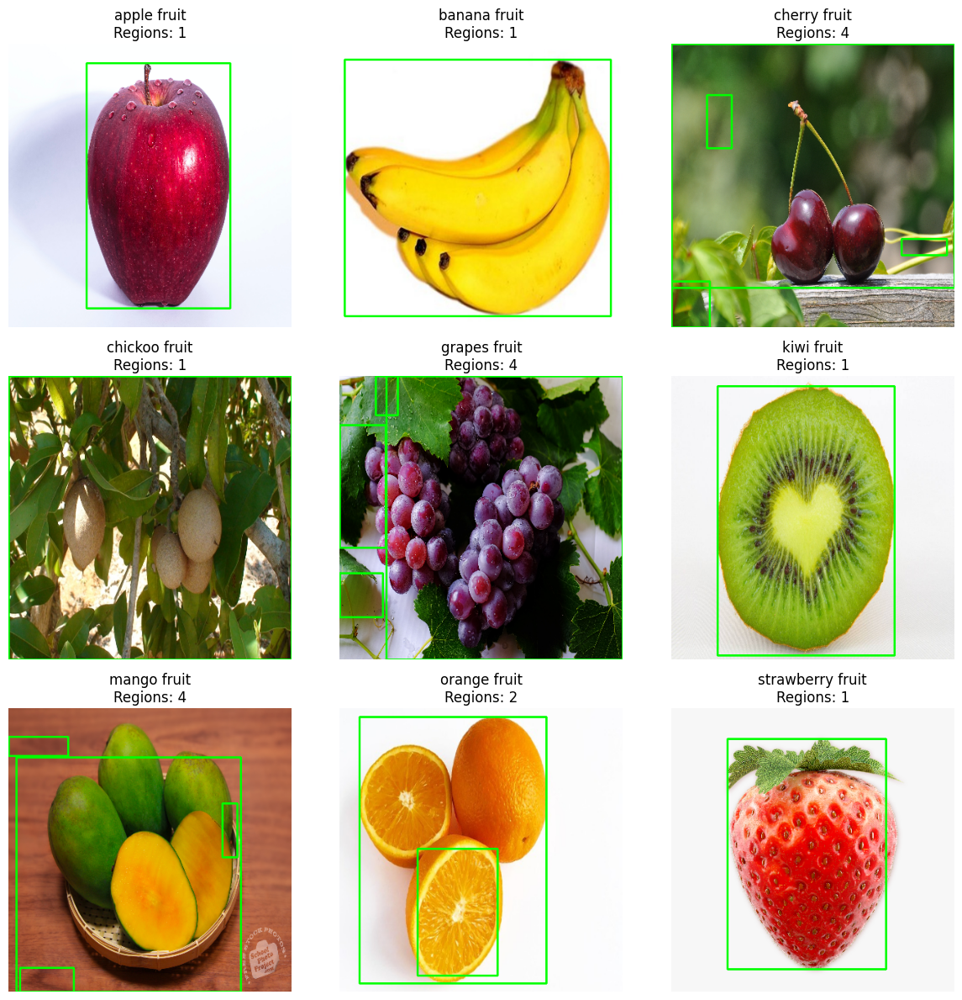

Contour detection results:
apple fruit: 1 region(s)
banana fruit: 1 region(s)
cherry fruit: 4 region(s)
chickoo fruit: 1 region(s)
grapes fruit: 4 region(s)
kiwi fruit: 1 region(s)
mango fruit: 4 region(s)
orange fruit: 2 region(s)
strawberry fruit: 1 region(s)


In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

fruit_folders = sorted([
    f for f in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, f))
])

results = []

plt.figure(figsize=(12, 12))

for i, fruit in enumerate(fruit_folders):
    folder_path = os.path.join(dataset_path, fruit)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_path = os.path.join(folder_path, image_files[0])
    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.resize(image, (400, 400))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, thresh = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    result = image.copy()
    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                result, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )
            count += 1

    results.append((fruit, count))

    plt.subplot(3, 3, len(results))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"{fruit}\nRegions: {count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Contour detection results:")
for fruit, count in results:
    print(f"{fruit}: {count} region(s)")

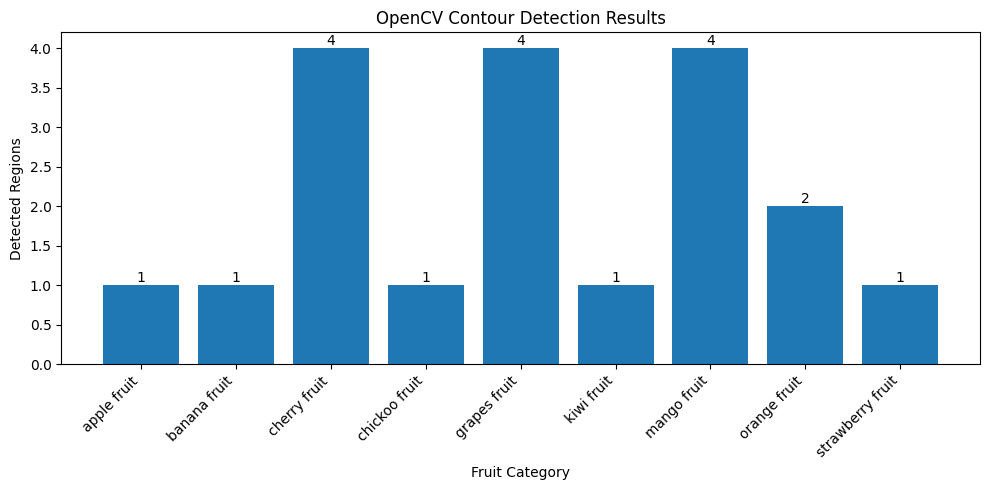

In [ ]:
import matplotlib.pyplot as plt

fruits = [item[0] for item in results]
counts = [item[1] for item in results]

plt.figure(figsize=(10, 5))

bars = plt.bar(fruits, counts)

plt.title("OpenCV Contour Detection Results")
plt.xlabel("Fruit Category")
plt.ylabel("Detected Regions")
plt.xticks(rotation=45, ha="right")
plt.bar_label(bars)

plt.tight_layout()
plt.show()

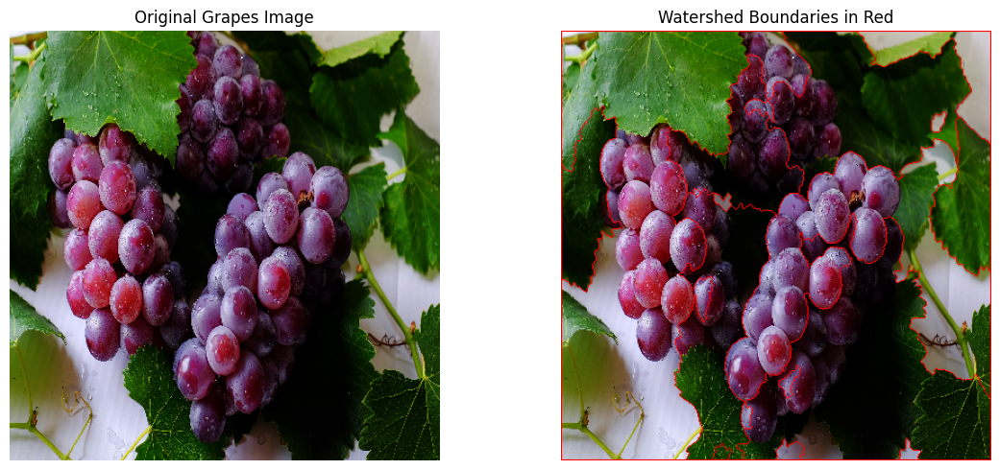

Estimated segmented regions: 7


In [ ]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

# Load one grapes image
folder = "/content/fruit_dataset/images/grapes fruit"

files = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image = cv2.imread(os.path.join(folder, files[0]))
image = cv2.resize(image, (400, 400))

# Convert to grayscale and create a binary image
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

_, binary = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=2
)

# Find sure background and foreground
sure_bg = cv2.dilate(opening, kernel, iterations=3)

distance = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(
    distance, 0.4 * distance.max(), 255, 0
)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# Watershed segmentation
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

segmented = image.copy()
markers = cv2.watershed(segmented, markers)
segmented[markers == -1] = [0, 0, 255]

# Count segmented foreground regions
labels = np.unique(markers)
count = 0

for label in labels:
    if label <= 1:
        continue

    region = np.uint8(markers == label)
    contours, _ = cv2.findContours(
        region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours and cv2.contourArea(max(contours, key=cv2.contourArea)) > 100:
        count += 1

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Grapes Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB))
plt.title("Watershed Boundaries in Red")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Estimated segmented regions:", count)

In [ ]:
import cv2
import os
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

def detect_regions(image_path):
    image = cv2.imread(image_path)

    if image is None:
        return None, 0

    image = cv2.resize(image, (400, 400))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    result = image.copy()
    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                result, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )
            count += 1

    return result, count


# Test five images from each category
records = []

for fruit in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, fruit)

    if not os.path.isdir(folder):
        continue

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ][:5]

    for filename in image_files:
        image_path = os.path.join(folder, filename)
        _, count = detect_regions(image_path)

        records.append({
            "Fruit Category": fruit,
            "Image": filename,
            "Detected Regions": count
        })

df_results = pd.DataFrame(records)

print(df_results.to_string(index=False))
print("\nImages tested:", len(df_results))
print("Average detected regions:",
      round(df_results["Detected Regions"].mean(), 2))

  Fruit Category        Image  Detected Regions
     apple fruit Image_3.jpeg                 1
     apple fruit Image_11.jpg                 1
     apple fruit Image_13.png                 1
     apple fruit Image_32.jpg                 1
     apple fruit Image_18.jpg                 1
    banana fruit Image_3.jpeg                 1
    banana fruit Image_11.jpg                 1
    banana fruit Image_32.jpg                 1
    banana fruit Image_18.jpg                10
    banana fruit  Image_6.jpg                 2
    cherry fruit Image_4.jpeg                 4
    cherry fruit Image_18.jpg                 2
    cherry fruit  Image_6.jpg                 2
    cherry fruit Image_16.jpg                 4
    cherry fruit Image_28.jpg                 7
   chickoo fruit Image_11.jpg                 1
   chickoo fruit Image_32.jpg                 1
   chickoo fruit Image_18.jpg                 1
   chickoo fruit  Image_6.jpg                 3
   chickoo fruit Image_16.jpg           

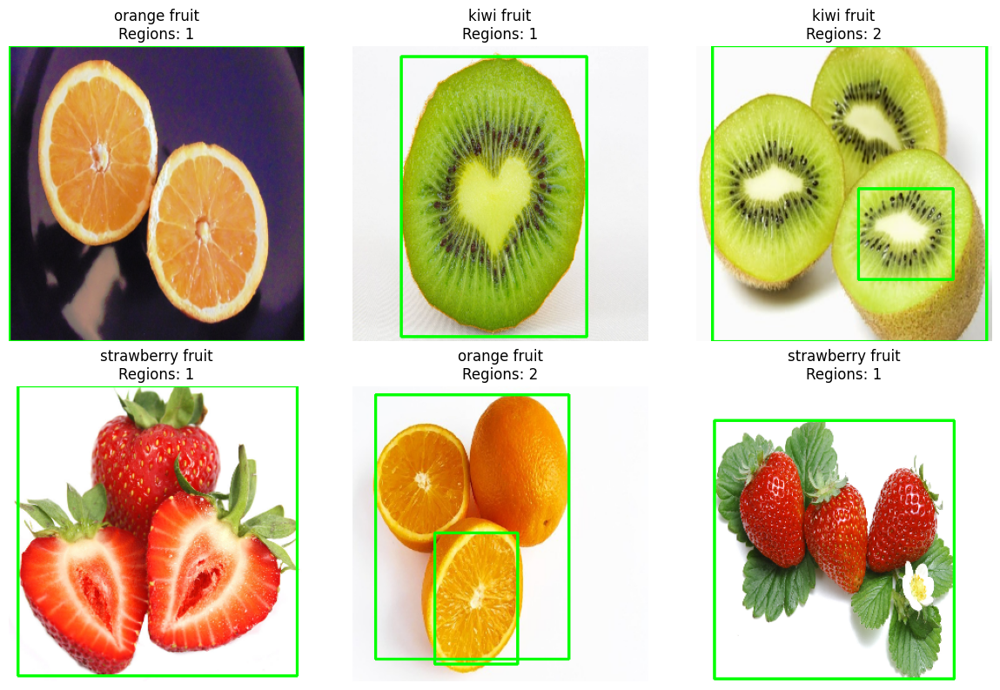

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

# Select six images from the test results
samples = df_results.sample(
    n=min(6, len(df_results)), random_state=42
)

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(samples.iterrows(), start=1):
    image_path = os.path.join(
        dataset_path, row["Fruit Category"], row["Image"]
    )

    image = cv2.imread(image_path)
    image = cv2.resize(image, (300, 300))

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    result = image.copy()

    for contour in contours:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                result, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )

    plt.subplot(2, 3, i)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(
        f'{row["Fruit Category"]}\n'
        f'Regions: {row["Detected Regions"]}'
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

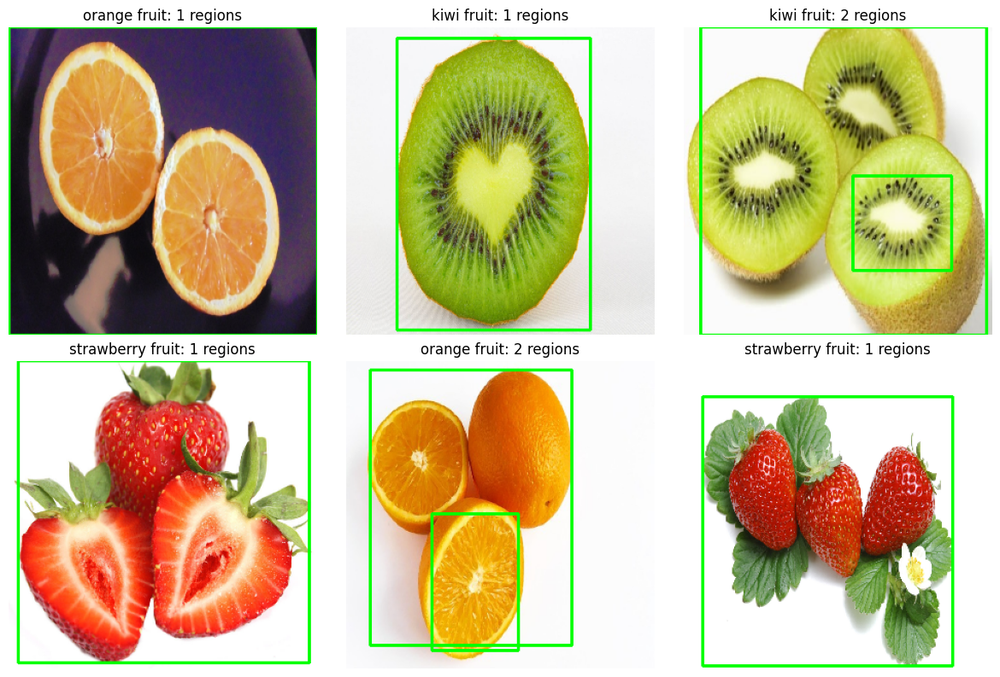

In [ ]:

import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

samples = df_results.sample(
    n=min(6, len(df_results)),
    random_state=42
)

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(samples.iterrows(), start=1):
    image_path = os.path.join(
        dataset_path,
        row["Fruit Category"],
        row["Image"]
    )

    image = cv2.imread(image_path)
    image = cv2.resize(image, (300, 300))

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                image,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )
            count += 1

    plt.subplot(2, 3, i)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f'{row["Fruit Category"]}: {count} regions')
    plt.axis("off")

plt.tight_layout()
plt.show()


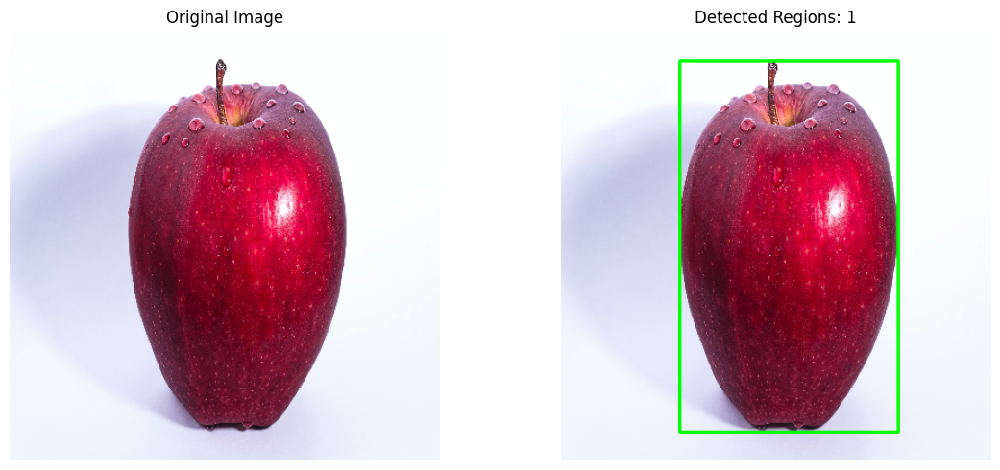

Detected regions: 1
Note: regions are estimates, not guaranteed fruit counts.


In [ ]:

import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

# Select one fruit image to test
fruit_folder = "apple fruit"
folder_path = os.path.join(dataset_path, fruit_folder)

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

image_path = os.path.join(folder_path, image_files[0])

image = cv2.imread(image_path)
image = cv2.resize(image, (400, 400))

# Convert to grayscale and reduce noise
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (7, 7), 0)

# Create a binary image
_, binary = cv2.threshold(
    blur, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Find outer contours
contours, _ = cv2.findContours(
    binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Keep only sufficiently large regions
output = image.copy()
fruit_count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 1000:
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(
            output, (x, y), (x + w, y + h), (0, 255, 0), 2
        )
        fruit_count += 1

# Display the result
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"Detected Regions: {fruit_count}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Detected regions:", fruit_count)
print("Note: regions are estimates, not guaranteed fruit counts.")


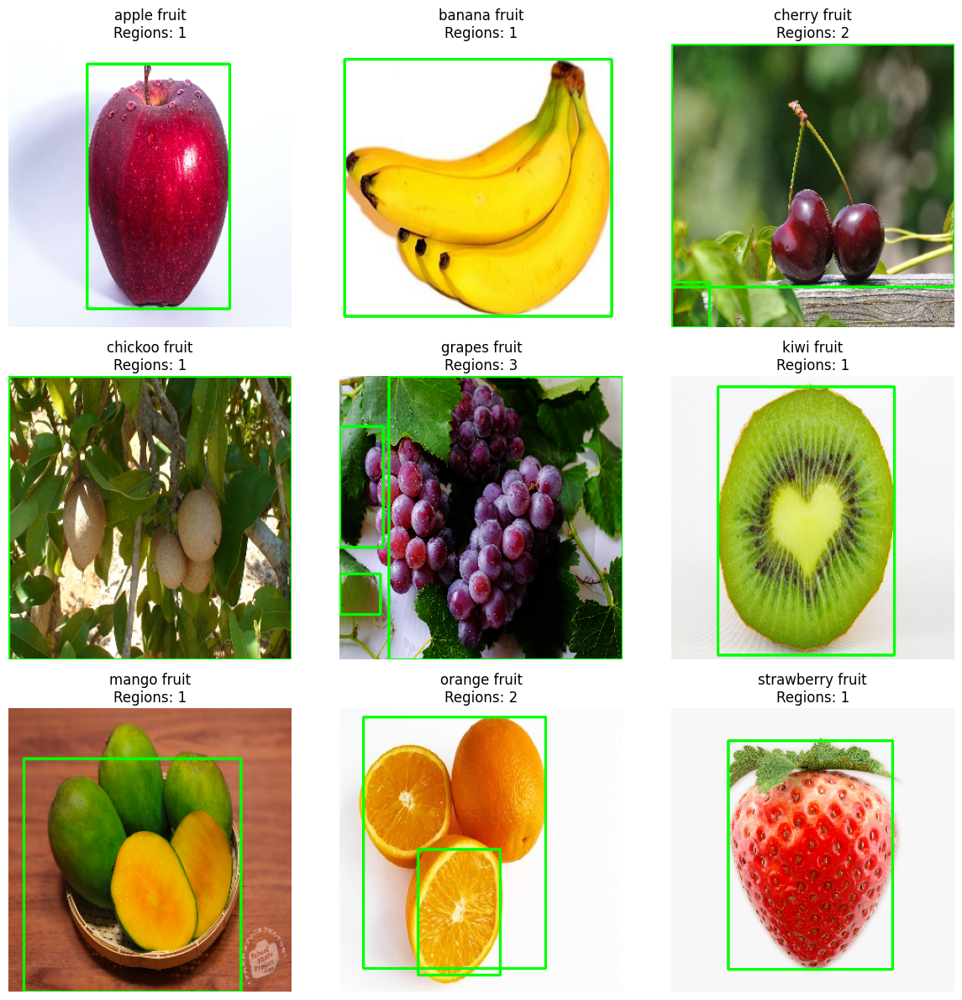

,Fruit Category,Detected Regions
0,apple fruit,1
1,banana fruit,1
2,cherry fruit,2
3,chickoo fruit,1
4,grapes fruit,3
5,kiwi fruit,1
6,mango fruit,1
7,orange fruit,2
8,strawberry fruit,1


In [ ]:

import cv2
import os
import matplotlib.pyplot as plt

dataset_path = "/content/fruit_dataset/images"

fruit_categories = [
    "apple fruit",
    "banana fruit",
    "cherry fruit",
    "chickoo fruit",
    "grapes fruit",
    "kiwi fruit",
    "mango fruit",
    "orange fruit",
    "strawberry fruit"
]

results_final = []

plt.figure(figsize=(12, 12))

for i, category in enumerate(fruit_categories, start=1):
    folder = os.path.join(dataset_path, category)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    if not files:
        print("No images found:", category)
        continue

    image_path = os.path.join(folder, files[0])
    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.resize(image, (300, 300))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)

    _, binary = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > 1000:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(
                image, (x, y), (x + w, y + h), (0, 255, 0), 2
            )
            count += 1

    results_final.append({
        "Fruit Category": category,
        "Detected Regions": count
    })

    plt.subplot(3, 3, i)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"{category}\nRegions: {count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

import pandas as pd

results_df = pd.DataFrame(results_final)
display(results_df)


In [ ]:

# Save the detection results
results_df.to_csv(
    "/content/fruit_counting_results.csv",
    index=False
)

print("Results saved successfully!")

# Download the CSV file
from google.colab import files
files.download("/content/fruit_counting_results.csv")


Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import zipfile

project_dir = "/content/fruit_counting_project"

os.makedirs(project_dir, exist_ok=True)
os.makedirs(f"{project_dir}/results", exist_ok=True)
os.makedirs(f"{project_dir}/screenshots", exist_ok=True)
os.makedirs(f"{project_dir}/dataset", exist_ok=True)

# Save the detection results table
results_df.to_csv(
    f"{project_dir}/results/fruit_detection_results.csv",
    index=False
)

# Save dataset information
with open(f"{project_dir}/dataset/README.md", "w") as f:
    f.write("""# Dataset Information

Dataset: Fruit image dataset
Categories: Apple, Banana, Cherry, Chickoo, Grapes,
Kiwi, Mango, Orange, Strawberry
Total images inspected: 359

Dataset location in Google Colab:
`/content/fruit_dataset/images`

The dataset was uploaded as a ZIP file and extracted
in Google Colab. Add the original dataset download
link here before publishing the project.
""")

print("Project folders created!")
print("Detection results saved!")


Project folders created!
Detection results saved!


In [ ]:

%%writefile /content/fruit_counting_project/fruit_counting.py

import cv2
import os
import pandas as pd

DATASET_PATH = "/content/fruit_dataset/images"
MIN_CONTOUR_AREA = 1000

FRUIT_CATEGORIES = [
    "apple fruit",
    "banana fruit",
    "cherry fruit",
    "chickoo fruit",
    "grapes fruit",
    "kiwi fruit",
    "mango fruit",
    "orange fruit",
    "strawberry fruit"
]

def count_fruit_regions(image_path):
    """Detect candidate fruit regions using OpenCV contours."""

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.resize(image, (400, 400))

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)

    _, binary = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    output = image.copy()
    count = 0

    for contour in contours:
        if cv2.contourArea(contour) > MIN_CONTOUR_AREA:
            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                output,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            count += 1

    return output, count


def main():
    results = []

    for category in FRUIT_CATEGORIES:
        folder = os.path.join(DATASET_PATH, category)

        if not os.path.isdir(folder):
            print(f"Skipping missing folder: {category}")
            continue

        image_files = sorted([
            name for name in os.listdir(folder)
            if name.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ])

        if not image_files:
            print(f"No images found in: {category}")
            continue

        image_path = os.path.join(folder, image_files[0])

        try:
            _, count = count_fruit_regions(image_path)

            results.append({
                "Fruit Category": category,
                "Image": image_files[0],
                "Detected Regions": count
            })

            print(f"{category}: {count} detected regions")

        except ValueError as error:
            print(error)

    os.makedirs("results", exist_ok=True)

    pd.DataFrame(results).to_csv(
        "results/fruit_detection_results.csv",
        index=False
    )

    print("\nResults saved to results/fruit_detection_results.csv")
    print("Note: detected regions are not guaranteed true fruit counts.")


if __name__ == "__main__":
    main()


Writing /content/fruit_counting_project/fruit_counting.py


In [ ]:

%%writefile /content/fruit_counting_project/requirements.txt

opencv-python
pandas
matplotlib


Writing /content/fruit_counting_project/requirements.txt


In [ ]:

%%writefile /content/fruit_counting_project/README.md

# Fruit Counting Using OpenCV

## 1. Problem Statement
Counting fruit regions in images automatically can help demonstrate
basic computer vision and image-processing techniques.

## 2. Objective
To process fruit images using OpenCV and detect candidate fruit
regions using contour detection.

## 3. Dataset
The dataset contains 359 images across nine categories:
- Apple
- Banana
- Cherry
- Chickoo
- Grapes
- Kiwi
- Mango
- Orange
- Strawberry

Dataset source: Add the original dataset download link here.

## 4. Methodology
1. Load the fruit image.
2. Resize the image.
3. Convert it to grayscale.
4. Apply Gaussian blur to reduce noise.
5. Apply Otsu thresholding.
6. Detect external contours.
7. Filter small contours by area.
8. Draw bounding boxes and count the remaining regions.

## 5. Tools and Libraries
- Python
- OpenCV
- Pandas
- Matplotlib

## 6. Results
The initial test on nine sample images produced 13 detected regions
in total.

These are candidate image regions, not verified fruit counts.
The method may overcount or miss fruits depending on image
background, lighting, overlap, and segmentation quality.

Detailed results are stored in:
`results/fruit_detection_results.csv`

## 7. Performance Evaluation
The current implementation reports detected-region counts.
Ground-truth annotations are not available, so accuracy, precision,
recall, and counting error have not yet been established.

## 8. Limitations
- Background objects may be detected as fruit regions.
- One fruit may produce multiple contours.
- Touching or overlapping fruits may be merged.
- Thresholding depends on lighting and image contrast.

## 9. Conclusion
This project demonstrates a basic OpenCV pipeline for fruit-region
detection. Further segmentation improvements or a trained object
detection model would be needed for reliable fruit counting.

## 10. How to Run
Install the dependencies:

    pip install -r requirements.txt

Ensure the dataset folders are available and update the dataset
path in the source code before running:

    python fruit_counting.py


Writing /content/fruit_counting_project/README.md


In [ ]:

import os
import zipfile

project_dir = "/content/fruit_counting_project"

# Create required folders
os.makedirs(f"{project_dir}/results", exist_ok=True)
os.makedirs(f"{project_dir}/screenshots", exist_ok=True)
os.makedirs(f"{project_dir}/dataset", exist_ok=True)
os.makedirs(f"{project_dir}/report", exist_ok=True)

# Check important files
required_files = [
    "fruit_counting.py",
    "requirements.txt",
    "README.md",
    "results/fruit_detection_results.csv"
]

print("Checking project files:")

for file in required_files:
    path = os.path.join(project_dir, file)
    print(("OK: " if os.path.exists(path) else "MISSING: ") + file)

# Create ZIP file
zip_path = "/content/fruit_counting_project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(project_dir):
        for file in files_list:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, project_dir)
            z.write(full_path, relative_path)

print("\nZIP file created:", zip_path)



Checking project files:
OK: fruit_counting.py
OK: requirements.txt
OK: README.md
OK: results/fruit_detection_results.csv

ZIP file created: /content/fruit_counting_project.zip


In [ ]:

from google.colab import files

files.download("/content/fruit_counting_project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>